In [1]:
pip install numpy pandas matplotlib scikit-learn


In [1]:
import pandas as pd
import numpy as np
data = {
    "size": [500, 700, 900, 1100, 1300, 1500, 1700, 1900],
    "price": [25, 35, 45, 55, 65, 75, 85, 95]
}

df = pd.DataFrame(data)
print(df)

   size  price
0   500     25
1   700     35
2   900     45
3  1100     55
4  1300     65
5  1500     75
6  1700     85
7  1900     95


**note:** df[["size"]] uses double brackets and returns a 2D DataFrame.
where as
df["price"] returns a 1D Series.

In [3]:
print(type(df['price']))
print(type(df[['size']]))

<class 'pandas.core.series.Series'>
<class 'pandas.core.frame.DataFrame'>


In [2]:
x=df[['size']]
y=df['price']

x is a 2 d arrray and y is 1d series

In [3]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=42)

In [4]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [7]:
print("Weight:", model.coef_)
print("Bias:", model.intercept_)

Weight: [0.05]
Bias: 1.4210854715202004e-14


In [8]:
new_houses = pd.DataFrame({
    "size": [1000, 2000, 2500]
})

In [9]:
predictions = model.predict(new_houses)
print(predictions)

[ 50. 100. 125.]


In [10]:
y_pred = model.predict(X_test)

In [11]:
print("Actual:", y_test.values)
print("Predicted:", y_pred)

Actual: [35 75]
Predicted: [35. 75.]


In [12]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [13]:
mean = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print("Mean Absolute Error:", mean)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R-squared:", r2)

Mean Absolute Error: 3.552713678800501e-15
Mean Squared Error: 2.524354896707238e-29
Root Mean Squared Error: 5.0242958677880805e-15
R-squared: 1.0


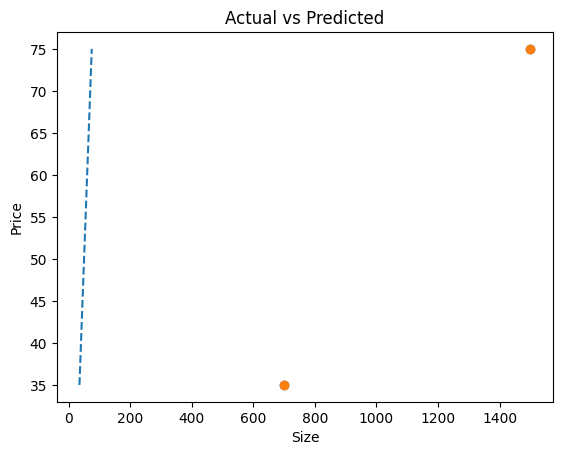

In [14]:
import matplotlib.pyplot as plt
plt.scatter(X_test, y_test)
plt.scatter(X_test, y_pred)
plt.xlabel("Size")
plt.ylabel("Price")
plt.title("Actual vs Predicted")

# Perfect prediction reference line
min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())
plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)
plt.show()

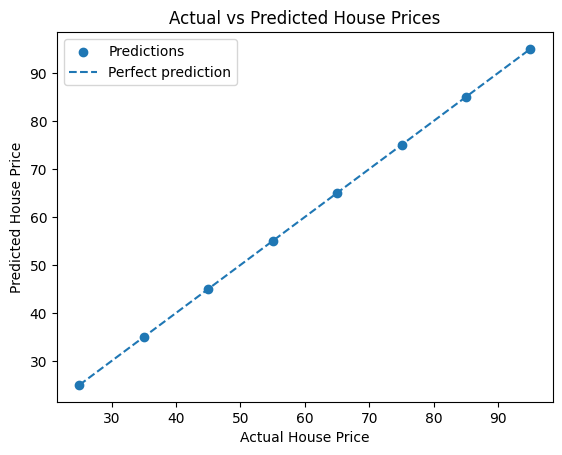

In [15]:
all_predictions = model.predict(x)

plt.scatter(y, all_predictions, label="Predictions")

min_price = min(y.min(), all_predictions.min())
max_price = max(y.max(), all_predictions.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted House Prices")
plt.legend()
plt.show()